In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, roc_auc_score)

In [2]:
colunas = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

df = pd.read_csv("processed.cleveland.data", header=None, names=colunas, na_values="?")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
print(df.shape)              
df.info()
print(df.isna().sum())    
df.describe()

(303, 14)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [ ]:
print("Antes:\n", df["target"].value_counts().sort_index())

df["target"] = (df["target"] > 0).astype(int) #0 indica ausencia de doença, maior que zero indica doença

print("\nDepois:\n", df["target"].value_counts())

Antes:
 target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Depois:
 target
0    164
1    139
Name: count, dtype: int64


In [5]:
X = df.drop(columns=["target"])
y = df["target"]

print(X.shape, y.shape) 

(303, 13) (303,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")   

Treino: 242 amostras
Teste:  61 amostras


In [ ]:
imputer = SimpleImputer(strategy="most_frequent")
X_train_imp = imputer.fit_transform(X_train)   
X_test_imp = imputer.transform(X_test)        

print("Ausentes no treino:", np.isnan(X_train_imp).sum())  

Ausentes no treino: 0


In [8]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_imp)
X_test_sc = scaler.transform(X_test_imp)

In [9]:
model = LogisticRegression(solver="liblinear", random_state=42, max_iter=1000)
model.fit(X_train_sc, y_train)

print("Itereaçoes até convergir:", model.n_iter_)

Itereaçoes até convergir: [5]


In [ ]:
y_pred = model.predict(X_test_sc) #chance da previsao estar certa
y_prob = model.predict_proba(X_test_sc)[:, 1] #chance de ter doença

In [ ]:
print(confusion_matrix(y_test, y_pred)) #ordem: VN, FP; FN, VP

[[27  6]
 [ 2 26]]


In [ ]:
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}") #acertos
print(f"Precisão: {precision_score(y_test, y_pred):.4f}") #dos marcados como doentes, quantos eram
print(f"Recall: {recall_score(y_test, y_pred):.4f}") #dos que eram doentes, quantos foram encontrados
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")  #equilibiro entre precisao e recall

Acurácia: 0.8689
Precisão: 0.8125
Recall: 0.9286
F1-Score: 0.8667


AUC-ROC: 0.9513


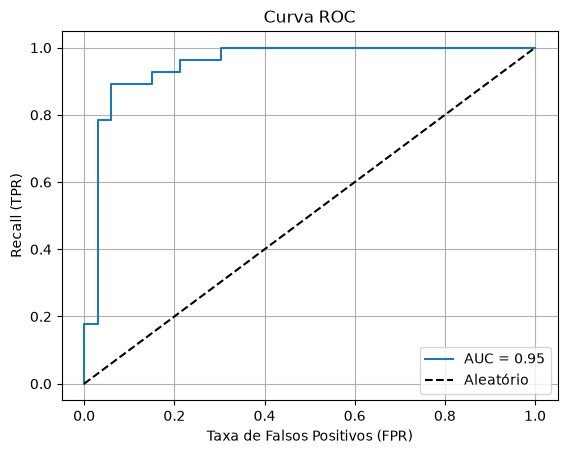

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob) #calcula a taxa de fp e vp e limiares
auc = roc_auc_score(y_test, y_prob)

print(f"AUC-ROC: {auc:.4f}")

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], "k--", label="Aleatório")
plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Recall (TPR)")
plt.title("Curva ROC")
plt.legend()
plt.grid(True)
plt.savefig("roc.png", dpi=150, bbox_inches="tight")
plt.show()